In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import poisson, expon, norm, lognorm

<h1>Poisson</h1>

Values of X: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Distribution: Poisson(lambda = 5 )
P(X = 0): 0.006737946999085467
P(X = 3): 0.1403738958142805
P(X = 5): 0.17546736976785068
PMF sum: 0.9999309917581438

X = 0
Theoretical PMF: 0.0067
Empirical PMF: 0.0074

X = 1
Theoretical PMF: 0.0337
Empirical PMF: 0.0355

X = 2
Theoretical PMF: 0.0842
Empirical PMF: 0.0862

X = 3
Theoretical PMF: 0.1404
Empirical PMF: 0.1436

X = 4
Theoretical PMF: 0.1755
Empirical PMF: 0.1722

X = 5
Theoretical PMF: 0.1755
Empirical PMF: 0.1726

X = 6
Theoretical PMF: 0.1462
Empirical PMF: 0.1486

X = 7
Theoretical PMF: 0.1044
Empirical PMF: 0.1015

X = 8
Theoretical PMF: 0.0653
Empirical PMF: 0.0648

X = 9
Theoretical PMF: 0.0363
Empirical PMF: 0.0388

X = 10
Theoretical PMF: 0.0181
Empirical PMF: 0.0158

X = 11
Theoretical PMF: 0.0082
Empirical PMF: 0.0067

X = 12
Theoretical PMF: 0.0034
Empirical PMF: 0.0035

X = 13
Theoretical PMF: 0.0013
Empirical PMF: 0.0017

X = 14
Theoretical PMF: 0.0005
E

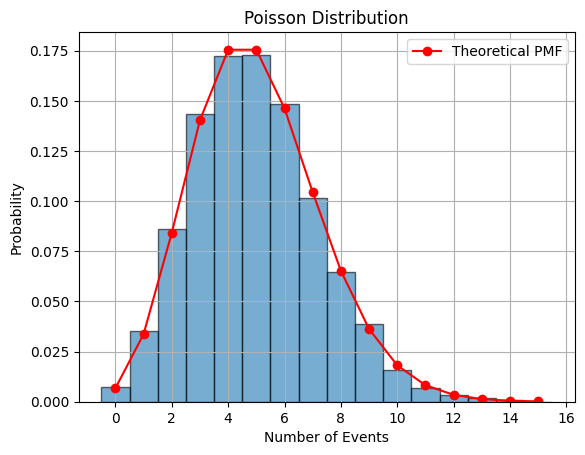

In [2]:
# Total average number of events
lam = 5

# Create a Poisson distribution object
X = poisson(mu=lam)

# Possible number of events
support = list(range(16))

print("Values of X:", support)
print("Distribution: Poisson(lambda =", lam, ")")

# Probability of exactly 0 events
print("P(X = 0):", X.pmf(0))

# Probability of exactly 3 events
print("P(X = 3):", X.pmf(3))

# Probability of exactly 5 events
print("P(X = 5):", X.pmf(5))

# Sum of probabilities over selected support
print("PMF sum:", sum(X.pmf(x) for x in support))

# Generate 10000 experiments
samples = np.random.poisson(lam=lam, size=10000)

# Theoretical and empirical PMF
for x in support:

    theoretical = X.pmf(x)
    empirical = np.mean(samples == x)

    print("\nX =", x)
    print("Theoretical PMF:", round(theoretical, 4))
    print("Empirical PMF:", round(empirical, 4))

# Histogram
plt.hist(samples, bins=np.arange(-0.5, 16.5, 1),
         density=True, alpha=0.6, edgecolor='black')

# Theoretical PMF
plt.plot(support, X.pmf(support), 'ro-', label="Theoretical PMF")

plt.title("Poisson Distribution")
plt.xlabel("Number of Events")
plt.ylabel("Probability")
plt.legend()
plt.grid()
plt.show()

<h1>Exponential Distribution

Distribution: Exponential(lambda = 2 )
P(X <= 1): 0.8646647167633873
P(X > 2): 0.01831563888873418
P(1 < X < 3): 0.13285653105994633

X = 0.0
Theoretical PDF: 2.0
Approx. Empirical Density: 0.935

X = 0.5
Theoretical PDF: 0.7358
Approx. Empirical Density: 0.747

X = 1.0
Theoretical PDF: 0.2707
Approx. Empirical Density: 0.2535

X = 1.5
Theoretical PDF: 0.0996
Approx. Empirical Density: 0.1

X = 2.0
Theoretical PDF: 0.0366
Approx. Empirical Density: 0.042

X = 2.5
Theoretical PDF: 0.0135
Approx. Empirical Density: 0.015

X = 3.0
Theoretical PDF: 0.005
Approx. Empirical Density: 0.006

X = 3.5
Theoretical PDF: 0.0018
Approx. Empirical Density: 0.003

X = 4.0
Theoretical PDF: 0.0007
Approx. Empirical Density: 0.0005

X = 4.5
Theoretical PDF: 0.0002
Approx. Empirical Density: 0.0

X = 5.0
Theoretical PDF: 0.0001
Approx. Empirical Density: 0.0


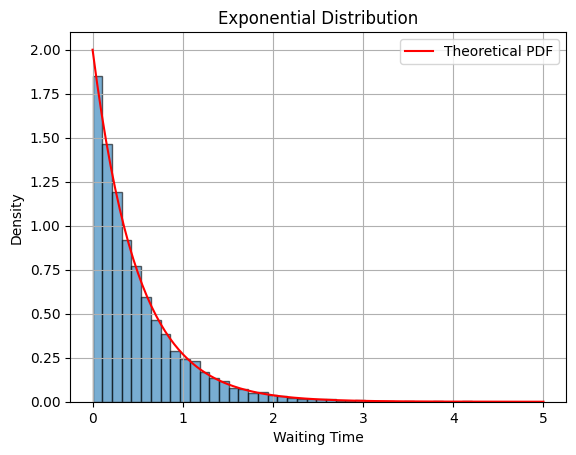

In [3]:
# Rate parameter
lam = 2

# Create an Exponential distribution object
# scale = 1/lambda
X = expon(scale=1/lam)

# Generate possible values
support = np.linspace(0, 5, 11)

print("Distribution: Exponential(lambda =", lam, ")")

# Probability using CDF
print("P(X <= 1):", X.cdf(1))

# Probability of waiting more than 2 units
print("P(X > 2):", X.sf(2))

# Probability between 1 and 3
print("P(1 < X < 3):", X.cdf(3) - X.cdf(1))

# Generate 10000 random samples
samples = np.random.exponential(scale=1/lam, size=10000)

# Theoretical PDF and empirical density
for x in support:

    theoretical = X.pdf(x)
    empirical = np.mean(
        (samples >= x - 0.1) & (samples < x + 0.1)
    ) / 0.2

    print("\nX =", round(x, 2))
    print("Theoretical PDF:", round(theoretical, 4))
    print("Approx. Empirical Density:", round(empirical, 4))

# Histogram
plt.hist(samples, bins=40, density=True,
         alpha=0.6, edgecolor='black')

# Theoretical PDF
x = np.linspace(0, 5, 200)
plt.plot(x, X.pdf(x), 'r-', label="Theoretical PDF")

plt.title("Exponential Distribution")
plt.xlabel("Waiting Time")
plt.ylabel("Density")
plt.legend()
plt.grid()
plt.show()

<h1>Normal

Distribution: Normal(mu = 50 , sigma = 10 )
PDF at X = 50: 0.03989422804014327
P(X < 60): 0.8413447460685429
P(X > 60): 0.15865525393145707
P(40 < X < 60): 0.6826894921370859

X = 20.0
Theoretical PDF: 0.0004
Approx. Empirical Density: 0.0004

X = 26.0
Theoretical PDF: 0.0022
Approx. Empirical Density: 0.0022

X = 32.0
Theoretical PDF: 0.0079
Approx. Empirical Density: 0.0084

X = 38.0
Theoretical PDF: 0.0194
Approx. Empirical Density: 0.0188

X = 44.0
Theoretical PDF: 0.0333
Approx. Empirical Density: 0.0331

X = 50.0
Theoretical PDF: 0.0399
Approx. Empirical Density: 0.0399

X = 56.0
Theoretical PDF: 0.0333
Approx. Empirical Density: 0.032

X = 62.0
Theoretical PDF: 0.0194
Approx. Empirical Density: 0.0206

X = 68.0
Theoretical PDF: 0.0079
Approx. Empirical Density: 0.008

X = 74.0
Theoretical PDF: 0.0022
Approx. Empirical Density: 0.002

X = 80.0
Theoretical PDF: 0.0004
Approx. Empirical Density: 0.0006


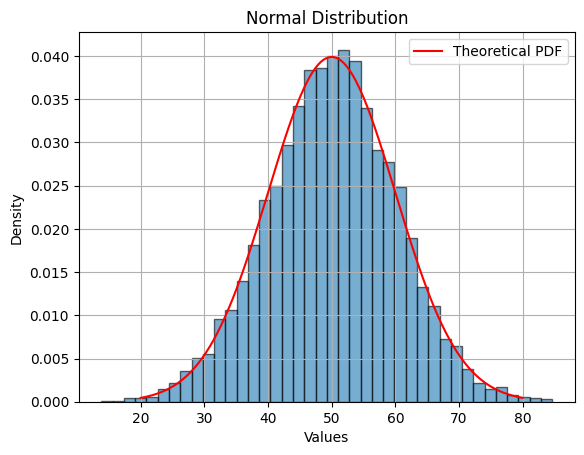

In [4]:
# Mean and standard deviation
mu = 50
sigma = 10

# Create a Normal distribution object
X = norm(loc=mu, scale=sigma)

# Possible values
support = np.linspace(20, 80, 11)

print("Distribution: Normal(mu =", mu, ", sigma =", sigma, ")")

# Probability density at x = 50
print("PDF at X = 50:", X.pdf(50))

# Probability that X is less than 60
print("P(X < 60):", X.cdf(60))

# Probability that X is greater than 60
print("P(X > 60):", X.sf(60))

# Probability between 40 and 60
print("P(40 < X < 60):", X.cdf(60) - X.cdf(40))

# Generate 10000 random samples
samples = np.random.normal(loc=mu, scale=sigma, size=10000)

# Theoretical PDF and approximate empirical density
for x in support:

    theoretical = X.pdf(x)

    empirical = np.mean(
        (samples >= x - 1) & (samples < x + 1)
    ) / 2

    print("\nX =", round(x, 2))
    print("Theoretical PDF:", round(theoretical, 4))
    print("Approx. Empirical Density:", round(empirical, 4))

# Histogram
plt.hist(samples, bins=40, density=True,
         alpha=0.6, edgecolor='black')

# Theoretical PDF
x = np.linspace(20, 80, 200)
plt.plot(x, X.pdf(x), 'r-', label="Theoretical PDF")

plt.title("Normal Distribution")
plt.xlabel("Values")
plt.ylabel("Density")
plt.legend()
plt.grid()
plt.show()

<h1>Log-Normal Distribution

Distribution: Log-Normal(mu = 0 , sigma = 0.5 )
PDF at X = 1: 0.7978845608028654
P(X < 1): 0.5
P(X > 2): 0.08282851900169846
P(1 < X < 2): 0.4171714809983016

X = 0.1
Theoretical PDF: 0.0002
Approx. Empirical Density: 0.007

X = 0.49
Theoretical PDF: 0.5885
Approx. Empirical Density: 1.169

X = 0.88
Theoretical PDF: 0.8775
Approx. Empirical Density: 1.778

X = 1.27
Theoretical PDF: 0.5604
Approx. Empirical Density: 1.105

X = 1.66
Theoretical PDF: 0.2876
Approx. Empirical Density: 0.542

X = 2.05
Theoretical PDF: 0.1389
Approx. Empirical Density: 0.263

X = 2.44
Theoretical PDF: 0.0666
Approx. Empirical Density: 0.12

X = 2.83
Theoretical PDF: 0.0324
Approx. Empirical Density: 0.069

X = 3.22
Theoretical PDF: 0.0161
Approx. Empirical Density: 0.032

X = 3.61
Theoretical PDF: 0.0082
Approx. Empirical Density: 0.011

X = 4.0
Theoretical PDF: 0.0043
Approx. Empirical Density: 0.005


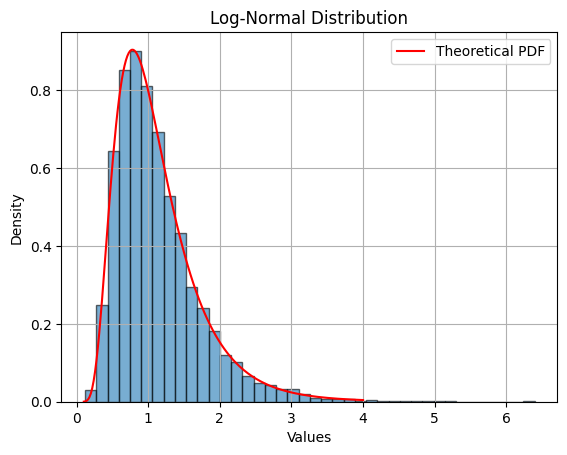

In [5]:
# Parameters of underlying normal distribution
mu = 0
sigma = 0.5

# Create a Log-Normal distribution object
# s = sigma
# scale = exp(mu)
X = lognorm(s=sigma, scale=np.exp(mu))

# Possible positive values
support = np.linspace(0.1, 4, 11)

print("Distribution: Log-Normal(mu =", mu,
      ", sigma =", sigma, ")")

# Probability density at x = 1
print("PDF at X = 1:", X.pdf(1))

# Probability that X is less than 1
print("P(X < 1):", X.cdf(1))

# Probability that X is greater than 2
print("P(X > 2):", X.sf(2))

# Probability between 1 and 2
print("P(1 < X < 2):", X.cdf(2) - X.cdf(1))

# Generate 10000 random samples
samples = np.random.lognormal(mean=mu, sigma=sigma, size=10000)

# Theoretical PDF and approximate empirical density
for x in support:

    theoretical = X.pdf(x)

    empirical = np.mean(
        (samples >= x - 0.1) & (samples < x + 0.1)
    ) / 0.1

    print("\nX =", round(x, 2))
    print("Theoretical PDF:", round(theoretical, 4))
    print("Approx. Empirical Density:", round(empirical, 4))

# Histogram
plt.hist(samples, bins=40, density=True,
         alpha=0.6, edgecolor='black')

# Theoretical PDF
x = np.linspace(0.1, 4, 200)
plt.plot(x, X.pdf(x), 'r-', label="Theoretical PDF")

plt.title("Log-Normal Distribution")
plt.xlabel("Values")
plt.ylabel("Density")
plt.legend()
plt.grid()
plt.show()

<h1>Standard Normal Distribution

Use: Normal distribution with mean 0 and standard deviation  1

Distribution: Standard Normal N(0,1)
PDF at Z = 0: 0.3989422804014327
P(Z < 1): 0.8413447460685429
P(Z > 1): 0.15865525393145707
P(-1 < Z < 1): 0.6826894921370859

Z = -4.0
Theoretical PDF: 0.0001
Approx. Empirical Density: 0.0

Z = -3.0
Theoretical PDF: 0.0044
Approx. Empirical Density: 0.0052

Z = -2.0
Theoretical PDF: 0.054
Approx. Empirical Density: 0.056

Z = -1.0
Theoretical PDF: 0.242
Approx. Empirical Density: 0.2542

Z = 0.0
Theoretical PDF: 0.3989
Approx. Empirical Density: 0.405

Z = 1.0
Theoretical PDF: 0.242
Approx. Empirical Density: 0.234

Z = 2.0
Theoretical PDF: 0.054
Approx. Empirical Density: 0.055

Z = 3.0
Theoretical PDF: 0.0044
Approx. Empirical Density: 0.0046

Z = 4.0
Theoretical PDF: 0.0001
Approx. Empirical Density: 0.0002


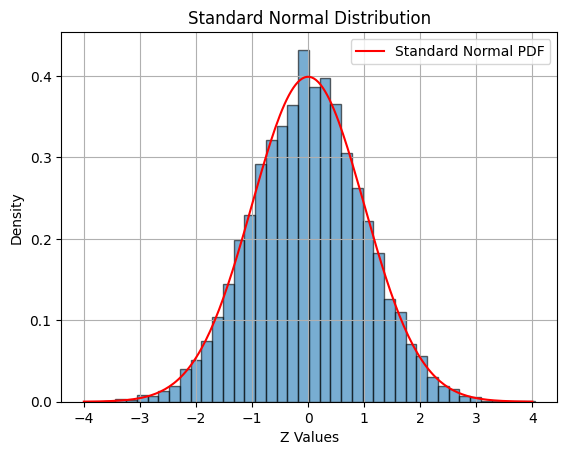

In [6]:
# Standard Normal Distribution
mu = 0
sigma = 1

# Create Standard Normal distribution object
Z = norm(loc=mu, scale=sigma)

# Possible Z values
support = np.linspace(-4, 4, 9)

print("Distribution: Standard Normal N(0,1)")

# PDF at Z = 0
print("PDF at Z = 0:", Z.pdf(0))

# Probability that Z is less than 1
print("P(Z < 1):", Z.cdf(1))

# Probability that Z is greater than 1
print("P(Z > 1):", Z.sf(1))

# Probability between -1 and 1
print("P(-1 < Z < 1):", Z.cdf(1) - Z.cdf(-1))

# Generate 10000 standard normal samples
samples = np.random.standard_normal(size=10000)

# Theoretical PDF and approximate empirical density
for z in support:

    theoretical = Z.pdf(z)

    empirical = np.mean(
        (samples >= z - 0.25) & (samples < z + 0.25)
    ) / 0.5

    print("\nZ =", round(z, 2))
    print("Theoretical PDF:", round(theoretical, 4))
    print("Approx. Empirical Density:", round(empirical, 4))

# Histogram
plt.hist(samples, bins=40, density=True,
         alpha=0.6, edgecolor='black')

# Theoretical PDF
z = np.linspace(-4, 4, 200)
plt.plot(z, Z.pdf(z), 'r-', label="Standard Normal PDF")

plt.title("Standard Normal Distribution")
plt.xlabel("Z Values")
plt.ylabel("Density")
plt.legend()
plt.grid()
plt.show()